# RecSys, HW1

## Рекомендательная система для SCP Foundation

[SCP Foundation](scpfoundation.net) — это международный коллективный литературный проект, представленный, в основном, стилизованными научно-фантастическими историями. Я буду рассматривать конкретно Российский филиал (оригинальные произведения и переводы). В каждой его статье присутствует одиннадцатибальный (пять звёзд, шаг 0.5) модуль рейтинга, информация об оценках публичная.

Чтобы удобно работать с замороженными во времени константными данными, я сделал выгрузку и прикладываю её на гитхабе в src папке.

### Prepare

In [1]:
from itertools import product
import matplotlib.pyplot as plt
import mplcyberpunk
import numpy as np
import polars as pl

seed = 55555
pl.set_random_seed(seed)

plt.style.use("cyberpunk")

In [2]:
votes = pl.read_csv("src/votes.csv", try_parse_dates=True).unique().sort("user_id", "article_id")
articles = pl.read_csv("src/articles.csv", try_parse_dates=True).unique().sort("id")
article_authors = pl.read_csv("src/article_authors.csv").unique().sort("article_id")
article_tags = pl.read_csv("src/article_tags.csv", try_parse_dates=True).unique().sort("article_id")

dfs = [votes, articles, article_tags, article_authors]
df_names = ["votes", "articles", "article_tags", "article_authors"]

### EDA

Для начала поймём, с какими вообще данными работаем.

In [3]:
votes.head(3)

rate,user_id,article_id,date
f64,i64,i64,"datetime[μs, UTC]"
4.5,7,434,2026-02-01 09:19:02.860763 UTC
3.0,7,4275,null
4.5,7,5898,2025-07-31 12:53:16.269412 UTC


In [4]:
articles.head(3)

id,parent_id,category,name,title
i64,i64,str,str,str
1,null,"""_default""","""sweetness""","""Золотце"""
2,null,"""_default""","""scp-2875""","""SCP-2875 - Город, вздрюченный …"
3,null,"""_default""","""scp-1097-ru""","""SCP-1097-RU - «Копир»"""


In [5]:
article_tags.head(3)

article_id,tag_id
i64,i64
1,965
1,469
1,377


In [6]:
article_authors.head(3)

article_id,user_id
i64,i64
1,2
2,5
3,3


Оставим только те статьи и тех юзеров, у которых есть взаимодействия. Также оставим только валидные взаимодействия.

In [7]:
rates = [0.5 * i for i in range(11)]
votes = votes.filter(pl.col("rate").is_in(rates))

user_ids = votes["user_id"].unique()
article_ids = votes["article_id"].unique()

articles = articles.filter(pl.col("id").is_in(article_ids.implode()))
article_tags = article_tags.filter(pl.col("article_id").is_in(article_ids.implode()))
article_authors = article_authors.filter(pl.col("article_id").is_in(article_ids.implode()))

Убедимся, что votes содержит только актуальные голоса (то есть что если пользователь переголосовал, то у него НЕ будет нескольких записей).

In [8]:
duplicates = (votes.group_by(["user_id", "article_id"]).len().filter(pl.col("len") > 1))
len(duplicates)

0

После очистки наконец можем посмотреть объёмы данных.

In [9]:
print(f"Votes amount: {len(votes)}")
print(f"Users amount: {len(user_ids)}")
print(f"Items amount: {len(articles)}")
print(f"Sparsity: {len(votes) / (len(user_ids) * len(articles))}")

Votes amount: 106975
Users amount: 3715
Items amount: 9109
Sparsity: 0.003161205835649507


Чтобы говорить о валидности очистки, осталось посмотреть пропуски:

In [10]:
for df, name in zip(dfs, df_names):
    null_counts = df.null_count().row(0)
    total_rows = df.height
    for column, count in zip(df.columns, null_counts):
        if count > 0:
            print(f"{name}->{column}: {count}/{total_rows} NULL")

votes->date: 18928/107003 NULL
articles->parent_id: 14513/16583 NULL


С `parent_id` всё понятно, статьи редко имеют родителя. Такое может встречаться только в циклах рассказов.

Даты оценок, к сожалению, фиксировались не с самого начала, можно сколлапсировать несуществующие даты до единой даты перед всеми остальными, что будет недалеко от правды.

In [11]:
old_votes = votes

votes = votes.with_columns(
    pl.col("date").fill_null(
        pl.col("date").min() - pl.duration(days=1)
    )
)

Итак, данные дедуплицированы и очищены, пропуски обоснованы, теперь ознакомимся с гистограммами, чтобы понять структуру взаимодействий, а также убедиться, что нет нереалистичных выбросов.

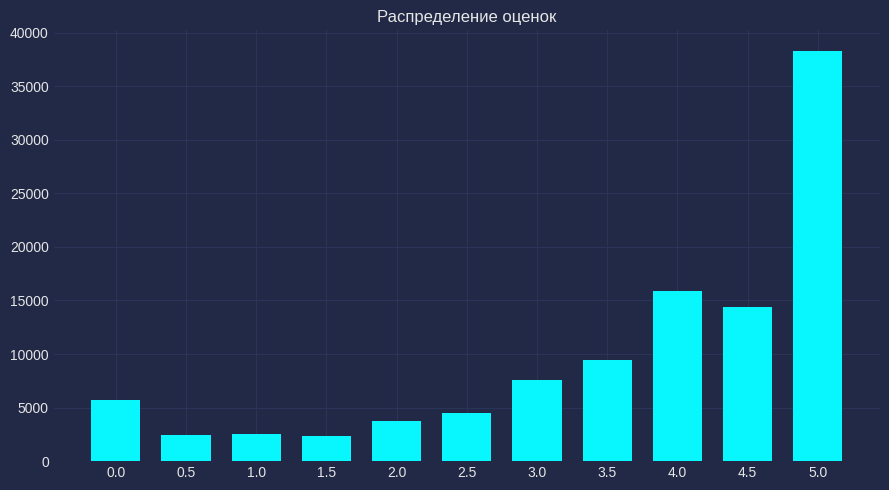

In [12]:
def get_bins(values):
    d = np.diff(np.unique(values)).min()
    left_of_first_bin = values.min() - float(d)/2
    right_of_last_bin = values.max() + float(d)/2
    return np.arange(left_of_first_bin, right_of_last_bin + d, d)

plt.figure(figsize=(9, 5))
values = votes["rate"]
plt.hist(values, bins=get_bins(values), rwidth=0.7)

plt.xticks(rates)
plt.title("Распределение оценок")
plt.tight_layout()
mplcyberpunk.add_glow_effects()
plt.show()

Больше всего голосов: 4037

Больше 1000 голосов: 11
250-1000 голосов: 76
100-250 голосов: 101


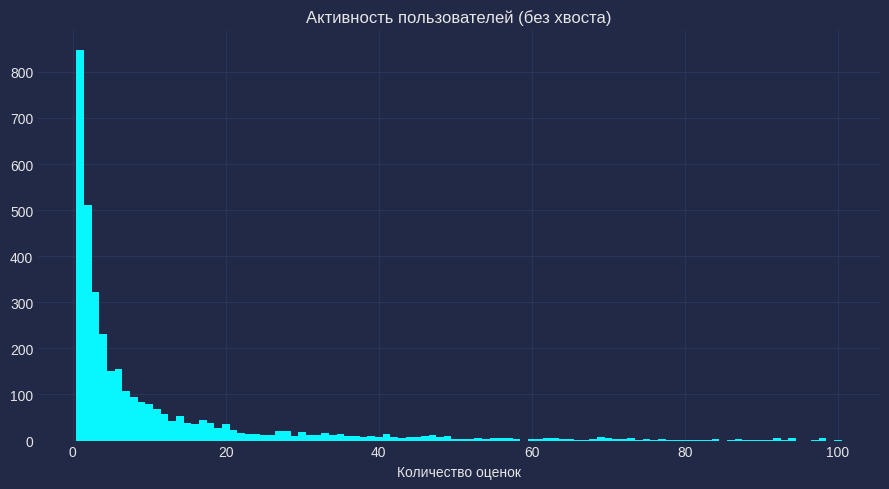

In [13]:
values = votes.group_by("user_id").len()["len"]
print(f"Больше всего голосов: {values.max()}")
print()
print(f"Больше 1000 голосов: {(values > 1000).sum()}")
print(f"250-1000 голосов: {((values > 250) & (values <= 1000)).sum()}")
print(f"100-250 голосов: {((values > 100) & (values <= 250)).sum()}")
values = values.to_numpy()
values = values[values <= 100]

plt.figure(figsize=(9, 5))
plt.hist(values, bins=get_bins(values))

plt.title("Активность пользователей (без хвоста)")
plt.xlabel("Количество оценок")
plt.tight_layout()
mplcyberpunk.add_glow_effects()
plt.show()

Больше всего голосов: 403

Больше 100 голосов: 44


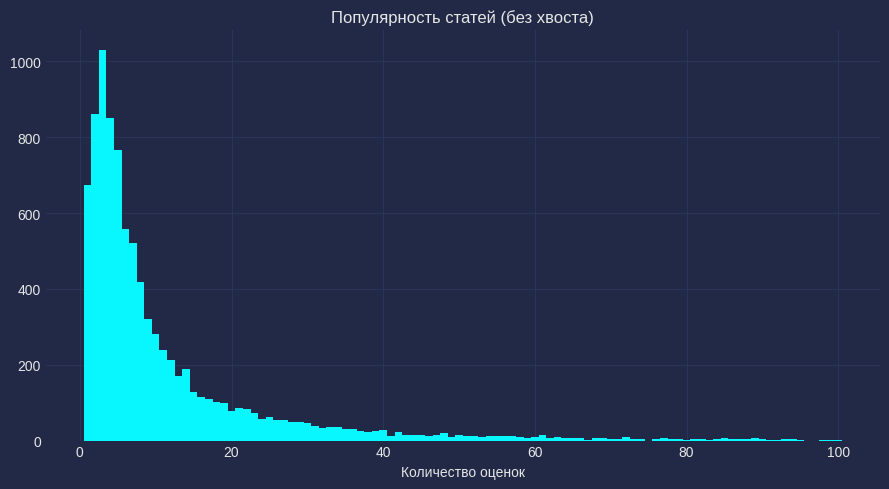

In [14]:
values = votes.group_by("article_id").len()["len"]
print(f"Больше всего голосов: {values.max()}")
print()
print(f"Больше 100 голосов: {(values > 100).sum()}")
values = values.to_numpy()
values = values[values <= 100]

plt.figure(figsize=(9, 5))
plt.hist(values, bins=get_bins(values))

plt.title("Популярность статей (без хвоста)")
plt.xlabel("Количество оценок")
plt.tight_layout()
mplcyberpunk.add_glow_effects()
plt.show()

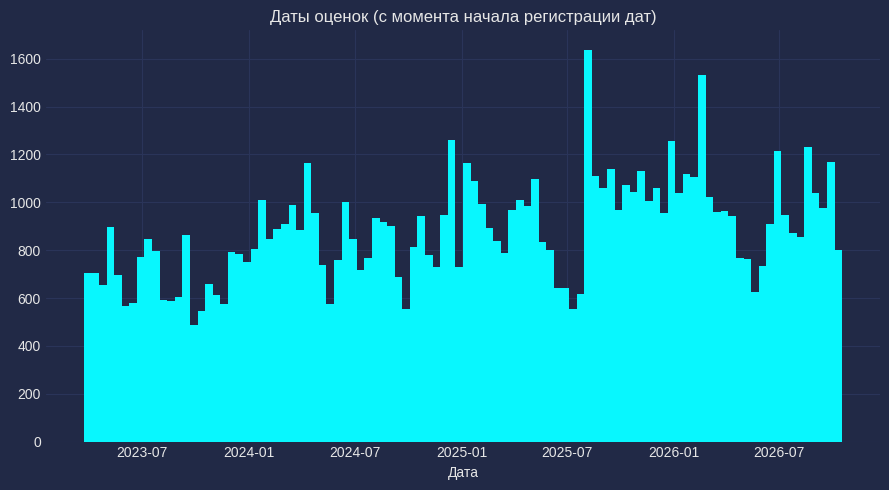

In [15]:
values = old_votes["date"]

plt.figure(figsize=(9, 5))
plt.hist(values, bins=100)

plt.title("Даты оценок (с момента начала регистрации дат)")
plt.xlabel("Дата")
plt.tight_layout()
mplcyberpunk.add_glow_effects()
plt.show()

Больше всего статей: 1054

Больше 1000 статей: 1
250-1000 статей: 4
50-250 статей: 21


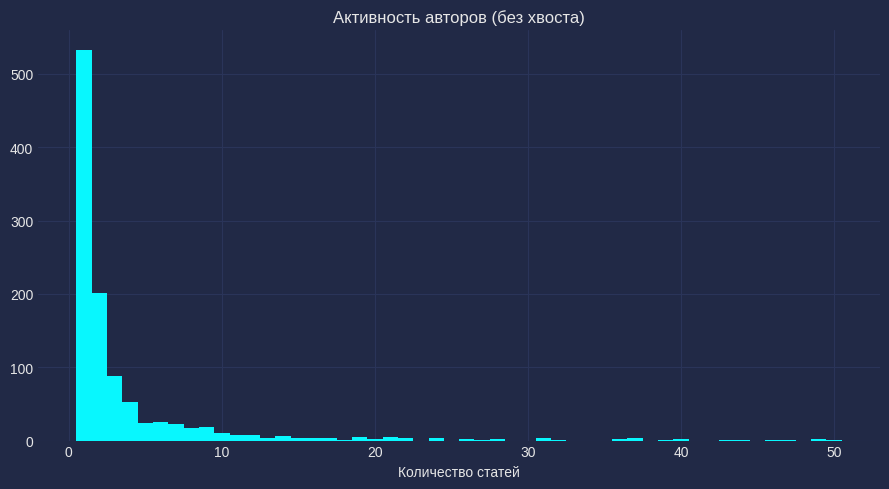

In [16]:
values = article_authors.group_by("user_id").len()["len"]
print(f"Больше всего статей: {values.max()}")
print()
print(f"Больше 1000 статей: {(values > 1000).sum()}")
print(f"250-1000 статей: {((values > 250) & (values <= 1000)).sum()}")
print(f"50-250 статей: {((values > 50) & (values <= 250)).sum()}")
values = values.to_numpy()
values = values[values <= 50]

plt.figure(figsize=(9, 5))
plt.hist(values, bins=get_bins(values))

plt.title("Активность авторов (без хвоста)")
plt.xlabel("Количество статей")
plt.tight_layout()
mplcyberpunk.add_glow_effects()
plt.show()

Наблюдаем неестественный эффект: при всём литературном таланте, вряд ли в проекте есть люди, реально написавшие больше 1000 статей. Да даже несколько десятков выглядит сомнительно.

Перепроверив информацию по сайту, я выяснил, что переводы получают авторство переводчика (так как иностранные авторы банально не зарегистрированы на нашем сайте по большей части), а также есть множество технических страниц, опубликованных админами.

Таким образом, в целом, метаинформация об авторстве может быть идейно очень полезной (если человеку нравятся статьи конкретного автора, то логично рекомендовать ему больше таких), но модель может запутаться из-за таких неестественных примесей, которые нам тяжело отделить. Вижу смысл в том, чтобы по возможности попробовать как учитывать авторов в метаинформации, так и не делать этого, и сравнить результаты.

### Протокол оценки

Данных не очень много, а так же мы говорим о литературном проекте, где не так важны тренды, и нет ничего страшного в том, чтобы рекомендовать статью десятилетней давности. Поэтому делим по каждому пользователю (стараясь отправить определённый процент от каджого пользователя в train, val и split), если у него хватает данных (хотя бы 5 оценок).

In [17]:
train_fraction = 0.8
val_fraction = 0.1
min_votes = 5

votes = votes.with_columns(
    pl.int_range(pl.len()).over("user_id").alias("_order")
).with_columns(
    pl.lit(seed).alias("_seed")
)

votes = votes.with_columns(
    pl.struct(["user_id", "_order", "_seed"])
    .hash(seed=seed)
    .alias("_random")
).sort(["user_id", "_random"])

votes = votes.with_columns(
    pl.int_range(pl.len()).over("user_id").alias("_idx"),
    pl.len().over("user_id").alias("_n"),
)

votes = votes.with_columns(
    pl.when(pl.col("_n") < min_votes)
    .then(pl.lit("train"))
    .when(pl.col("_idx") < (pl.col("_n") * train_fraction).floor())
    .then(pl.lit("train"))
    .when(
        pl.col("_idx")
        < (pl.col("_n") * train_fraction).floor()
        + ((pl.col("_n") * val_fraction).floor()).clip(lower_bound=1)
    )
    .then(pl.lit("validation"))
    .otherwise(pl.lit("test"))
    .alias("_split")
)

train = votes.filter(pl.col("_split") == "train").drop(
    "_order", "_seed", "_random", "_idx", "_n", "_split"
)
validation = votes.filter(pl.col("_split") == "validation").drop(
    "_order", "_seed", "_random", "_idx", "_n", "_split"
)
test = votes.filter(pl.col("_split") == "test").drop(
    "_order", "_seed", "_random", "_idx", "_n", "_split"
)

print(f"Train:      {train.height:,} взаимодействий")
print(f"Validation: {validation.height:,} взаимодействий")
print(f"Test:       {test.height:,} взаимодействий")

Train:      85,609 взаимодействий
Validation: 10,039 взаимодействий
Test:       11,327 взаимодействий


In [18]:
# Articles
articles_ids = np.sort(articles["id"].unique().to_numpy())
articles_ids_set = set(articles_ids.tolist())
train_articles_ids = set(train["article_id"].unique().to_list())

print(f"Статей всего: {len(articles_ids):,}")
print(f"Из них НЕТ информации в train: {len(articles_ids_set - train_articles_ids):,}")

# Users
users_ids = np.sort(votes["user_id"].unique().to_numpy())
users_ids_set = set(users_ids.tolist())
train_users_ids = set(train["user_id"].unique().to_list())

print(f"Пользователей всего: {len(users_ids):,}")
print(f"Из них НЕТ информации в train: {len(users_ids_set - train_users_ids):,}")

Статей всего: 9,109
Из них НЕТ информации в train: 172
Пользователей всего: 3,715
Из них НЕТ информации в train: 0


В целом, модель должна работать и с такими данными: статьи без информации надо рекомендовать иногда как novelty, а для новых пользователей предлагать самые популярные статьи. Но это скорее бизнес-логика из этапа reranking, нам не нужно обучать на ней.

По метрике выбор для нас практически безальтернативен: мы хотим учитывать разную степень релевантности (раз уж одиннадцать возможных значений оценок), а значит берём NDCG@k (остальные обычно сводят к бинарной релевантности-нерелевантности объектов).

In [19]:
NEUTRALITY_RATE = 3.25

def build_eval_data(heldout, fit_data, catalog_ids):
    seen = {
        int(user_id): set(map(int, article_ids))
        for user_id, article_ids in (
            fit_data.group_by("user_id")
            .agg(pl.col("article_id"))
            .iter_rows()
        )
    }

    relevant = heldout.filter(
        pl.col("rate") >= NEUTRALITY_RATE
    ).select(
        "user_id",
        "article_id",
        (pl.col("rate") - NEUTRALITY_RATE).alias("relevance"),
    )
    
    truth = {}
    for user_id, article_id, relevance in relevant.iter_rows():
        user_id = int(user_id)
        article_id = int(article_id)

        truth.setdefault(user_id, {})[article_id] = float(relevance)

    users = sorted(truth)
    users = [user_id for user_id in users if user_id in seen]

    return {
        "truth": truth,
        "seen": seen,
        "users": users,
        "catalog_ids": catalog_ids,
    }

In [20]:
catalog_ids = np.sort(articles["id"].unique().to_numpy())

validation_data = build_eval_data(
    validation,
    train,
    catalog_ids
)

train_validation = pl.concat([train, validation])
test_data = build_eval_data(
    test,
    train_validation,
    catalog_ids
)

article_info = (
    articles.select(
        pl.col("id").alias("article_id"),
        "title",
        "name",
    ).unique("article_id")
)

In [21]:
def count_NDCGk(
    model,
    eval_data,
    k=10,
    linear_gain=False,
):
    truth = eval_data["truth"]
    seen = eval_data["seen"]
    catalog_ids = eval_data["catalog_ids"]

    ndcgs = []
    for user_id in eval_data["users"]:
        relevant = truth[user_id]
        
        candidates = np.asarray([
            item_id
            for item_id in catalog_ids
            if item_id not in seen[user_id]
        ])
        candidates_set = set(candidates)

        recommendations = model.recommend(user_id, k)[:k]["article_id"]

        filtered = []
        used = set()
        for item_id in recommendations:
            item_id = int(item_id)
            if (
                item_id not in seen[user_id]
                and item_id in candidates_set
                and item_id not in used
            ):
                filtered.append(item_id)
                used.add(item_id)
        hits = [item for item in filtered if item in relevant]

        if linear_gain:
            gain = lambda relevance: max(0.0, relevance)
        else:
            gain = lambda relevance: 2 ** relevance - 1
            
        dcg = sum(
            gain(relevant[item]) / np.log2(rank + 2)
            for rank, item in enumerate(filtered)
            if item in relevant
        )

        ideal_relevance = sorted(
            relevant.values(), reverse=True
        )[:k]

        idcg = sum(
            gain(relevance) / np.log2(rank + 2)
            for rank, relevance in enumerate(ideal_relevance)
        )

        ndcgs.append(dcg / idcg if idcg > 0 else 0.0)

    return float(np.mean(ndcgs))

def count_Recallk(
    model,
    eval_data,
    k=10,
):
    truth = eval_data["truth"]
    seen = eval_data["seen"]
    catalog_ids = eval_data["catalog_ids"]

    recalls = []
    for user_id in eval_data["users"]:
        relevant = truth[user_id]

        candidates_set = {
            item_id
            for item_id in catalog_ids
            if item_id not in seen[user_id]
        }

        recommendations = model.recommend(user_id, k)[:k]["article_id"]

        filtered = []
        used = set()
        for item_id in recommendations:
            item_id = int(item_id)
            if (
                item_id not in seen[user_id]
                and item_id in candidates_set
                and item_id not in used
            ):
                filtered.append(item_id)
                used.add(item_id)

        hits = sum(item in relevant for item in filtered)
        recalls.append(hits / len(relevant) if relevant else 0.0)

    return float(np.mean(recalls))

def tune_model(
    model_cls,
    param_grid,
    train,
    validation_data,
    fit_kwargs=None,
    k=10,
):
    fit_kwargs = fit_kwargs or {}
    names = list(param_grid)
    results = []

    for values in product(*(param_grid[name] for name in names)):
        params = dict(zip(names, values))

        model = model_cls(**params)
        model.fit(train, **fit_kwargs)

        NDCGk = count_NDCGk(
            model=model,
            eval_data=validation_data,
            k=k,
        )

        results.append({
            **params,
            "metric": NDCGk,
        })

    results = pl.DataFrame(results).sort("metric", descending=True)

    best_params = {
        name: results[name][0]
        for name in names
    }

    return best_params, results

### Baseline

In [22]:
from models.baseline import PopularityModel

base = PopularityModel().fit(train_validation)
print(f"NDCG@10 for popular articles baseline: {round(count_NDCGk(base, test_data, 10), 3)}")

NDCG@10 for popular articles baseline: 0.036


### Collaborative Filtering

Я выбрал I2I, потому что схожесть между фиксированными текстовыми статьями вычислять логичнее, чем между изменчивыми пользователями. К тому же, если предположить возможность дальнейшего развития этой модели, по статьям будет гораздо больше метаинформации, по которой можно искать похожесть. Вплоть до того, что при желании можно будет буквально обучить эмбеддинг самого текста статей.

In [23]:
from models.item2item import ItemItemCF

param_grid = {
    "n_neighbors": [25, 50],
    "min_common": [2, 4],
    "shrinkage": [10.0],
    "damping": [1.0, 2.0]
}
best, every = tune_model(ItemItemCF, param_grid, train, validation_data)
print(best, every)

{'n_neighbors': 25, 'min_common': 2, 'shrinkage': 10.0, 'damping': 2.0} shape: (8, 5)
┌─────────────┬────────────┬───────────┬─────────┬──────────┐
│ n_neighbors ┆ min_common ┆ shrinkage ┆ damping ┆ metric   │
│ ---         ┆ ---        ┆ ---       ┆ ---     ┆ ---      │
│ i64         ┆ i64        ┆ f64       ┆ f64     ┆ f64      │
╞═════════════╪════════════╪═══════════╪═════════╪══════════╡
│ 25          ┆ 2          ┆ 10.0      ┆ 2.0     ┆ 0.043092 │
│ 25          ┆ 4          ┆ 10.0      ┆ 2.0     ┆ 0.043089 │
│ 25          ┆ 2          ┆ 10.0      ┆ 1.0     ┆ 0.041364 │
│ 25          ┆ 4          ┆ 10.0      ┆ 1.0     ┆ 0.041255 │
│ 50          ┆ 4          ┆ 10.0      ┆ 2.0     ┆ 0.04007  │
│ 50          ┆ 2          ┆ 10.0      ┆ 2.0     ┆ 0.038678 │
│ 50          ┆ 4          ┆ 10.0      ┆ 1.0     ┆ 0.03756  │
│ 50          ┆ 2          ┆ 10.0      ┆ 1.0     ┆ 0.037198 │
└─────────────┴────────────┴───────────┴─────────┴──────────┘


In [24]:
catalog_ids = articles["id"].unique().to_list()

i2i = ItemItemCF(**best).fit(train_validation, catalog_ids=catalog_ids)

Проверю результат на минимальную адекватность на себе и некоторых своих статьях.

In [25]:
MINE_UID = 632
MINE_ARTICLES_IDS = [
    2603, # SCP-1088-RU - Из Москвы во Владивосток за 5 минут: история о неудачном Советском аномальном эксперименте
    14412 # Дѣло о загадочномъ убіеніи брандмейстера: детектив в сеттинге Российской Империи 19 века
]

def show_articles(result):
    return (
        result.join(article_info, on="article_id", how="left").select(
            "article_id",
            "title",
            "name",
            *[c for c in result.columns if c not in ("article_id", "title", "name")],
        )
    )

In [26]:
# old_i2i = ItemItemCF(
#     n_neighbors=40,
#     min_common=1,
#     shrinkage=5.0,
#     damping=2.0,
# ).fit(train, catalog_ids=catalog_ids)
# print(count_NDCGk(old_i2i, validation_data, 5))
# print(count_NDCGk(i2i, validation_data, 5))
# print(count_NDCGk(model, validation_data, 5))
print("NDCG@10:")
print(count_NDCGk(i2i, test_data, 10))

print("Рекомендации для меня")
display(show_articles(i2i.recommend(MINE_UID, n=10)))

print("Похожие на SCP-1088-RU статьи")
display(show_articles(i2i.nearest_items(MINE_ARTICLES_IDS[0], n=10).with_columns(pl.col("similarity").round(3))))

print("Похожие на рассказ статьи")
display(show_articles(i2i.nearest_items(MINE_ARTICLES_IDS[1], n=10).with_columns(pl.col("similarity").round(3))))

NDCG@10:
0.048735284822368635
Рекомендации для меня


article_id,title,name,score
i64,str,str,f64
7481,"""Один день в Зоне 88""","""one-day-in-site-88""",3.927924
14528,"""SCP-1500-RU - Комитет по этике…","""scp-1500-ru""",3.923101
12867,"""SCP-1488-RU - Горячая линия сп…","""scp-1488-ru""",3.848182
8612,"""SCP-1001-RU - Пустотная сингул…","""scp-1001-ru""",3.847473
9661,"""Синдром гидрофобного божества""","""gods-hydrophobia-syndrome""",3.809676
14571,"""О технических нюансах при пере…","""on-technical-nuances-of-transl…",3.765734
5580,"""SCP-1344-RU - дадо маркет""","""scp-1344-ru""",3.697886
12079,"""SCP-1429-RU - Человек в замке""","""scp-1429-ru""",3.684038
9239,"""SCP-1984-J - Буквально 1984""","""scp-1984-j""",3.639076


Похожие на SCP-1088-RU статьи


article_id,title,name,similarity,shared_users
i64,str,str,f64,i64
3372,"""SCP-1028-RU - Спички""","""scp-1028-ru""",0.163,16
626,"""SCP-1400-RU - Фамеин""","""scp-1400-ru""",0.16,9
16037,"""SCP-1414-RU-EX - Катастрофа ша…","""scp-1414-ru-ex""",0.158,16
11570,"""SCP-1095-RU - Интернет (не) ан…","""scp-1095-ru""",0.14,16
6494,"""SCP-1402-RU - Смерть, великий …","""scp-1402-ru""",0.139,11
6281,"""SCP-2188 - Жизнь и времена Хоа…","""scp-2188""",0.137,5
5591,"""SCP-1983-RU - Я помню 04 ноябр…","""scp-1983-ru""",0.133,17
4834,"""SCP-1331-RU - Terra Incognita""","""scp-1331-ru""",0.129,11
5661,"""[ИСКЛЮЧЕНО СОГЛАСНО ПРОТОКОЛУ …","""taboo""",0.128,15


Похожие на рассказ статьи


article_id,title,name,similarity,shared_users
i64,str,str,f64,i64
14528,"""SCP-1500-RU - Комитет по этике…","""scp-1500-ru""",0.227,13
10614,"""Художественный перевод: от осн…","""the-art-of-translation""",0.223,9
15403,"""Оффсеты для «чайников»: пособи…","""offsets-for-dummies""",0.216,8
14571,"""О технических нюансах при пере…","""on-technical-nuances-of-transl…",0.2,10
2293,"""SCP-003-H - Нормальность превы…","""scp-003-h""",0.184,9
16699,"""Коллекция стилей Мити""","""mitya_styles""",0.183,9
13546,"""Вспышка""","""flash""",0.183,10
16809,"""SCP-3100-RU-J - Утонул чайный …","""scp-3100-ru-j""",0.178,12
16867,"""Нехарактерно агрессивная писат…","""anomalously-toxic-community""",0.178,11


Несмотря на кажущуюся плохой метрику, я могу сказать, что это не случайный набор предметов, и модель неплохо отработала с субъективной стороны. Мои рекомендации имеют смысл, как и похожесть я оцениваю логично (в том числе для SCP-1088-RU на 3 месте другая моя статья, а для рассказа логично увидеть в рекомендациях больше рассказов).

Теперь на всякий случай посмотрим, как себя на тех же данных показывает **библиотечная** реализация: я нигде её дальше не использую, просто любопытно посмотреть один раз здесь.

In [40]:
# pip install implicit
import numpy as np, polars as pl, scipy.sparse as sp
from implicit.nearest_neighbours import BM25Recommender, CosineRecommender, TFIDFRecommender

class ImplicitItemKNN:
    def __init__(self, kind="bm25", K=50, min_rate=3.25, weight="binary", **kw):
        self.cls = {"bm25": BM25Recommender, "cosine": CosineRecommender,
                    "tfidf": TFIDFRecommender}[kind]
        self.K, self.min_rate, self.weight, self.kw = K, min_rate, weight, kw

    def fit(self, votes, catalog_ids=None):
        v = votes.filter(pl.col("rate") >= self.min_rate)
        users = v["user_id"].unique().sort().to_numpy()
        items = v["article_id"].unique().sort().to_numpy()
        self.uid = {int(u): i for i, u in enumerate(users)}
        self.iid = {int(a): i for i, a in enumerate(items)}
        self.items = items

        rows = v["user_id"].replace_strict(self.uid, return_dtype=pl.Int64).to_numpy()
        cols = v["article_id"].replace_strict(self.iid, return_dtype=pl.Int64).to_numpy()
        w = (np.ones(len(v)) if self.weight == "binary"
             else v["rate"].to_numpy() - self.min_rate + 1.0)   # 3.5 -> 1.25, 5 -> 2.75
        self.ui = sp.csr_matrix((w.astype(np.float32), (rows, cols)),
                                shape=(len(users), len(items)))

        self.model = self.cls(K=self.K, **self.kw)
        self.model.fit(self.ui, show_progress=False)
        return self

    def recommend(self, user_id, n=10):
        u = self.uid.get(int(user_id))
        if u is None:
            return pl.DataFrame(schema={"article_id": pl.Int64, "score": pl.Float64})
        ids, sc = self.model.recommend(u, self.ui[u], N=n, filter_already_liked_items=True)
        return pl.DataFrame({"article_id": self.items[ids].astype(np.int64),
                             "score": sc.astype(np.float64)})

    def nearest_items(self, article_id, n=10):
        ids, sc = self.model.similar_items(self.iid[int(article_id)], N=n + 1)
        return pl.DataFrame({"article_id": self.items[ids][1:], "similarity": sc[1:]})

In [42]:
param_grid = {
    "kind": ["bm25", "cosine", "tfidf"],
    "kind": ["cosine"],
    "K": [25, 50, 100],
    "weight": ["binary", "rate"],
}
best_imp, imp_summary = tune_model(ImplicitItemKNN, param_grid, train, validation_data)

i2i_imp = ImplicitItemKNN(**best_imp).fit(train_validation, catalog_ids)
print(count_NDCGk(i2i_imp, test_data, 10))
show_articles(i2i_imp.recommend(MINE_UID, 10))

/home/evgeniy/.local/lib/python3.10/site-packages/implicit/utils.py:164: ParameterWarning: Method expects CSR input, and was passed coo_matrix instead. Converting to CSR took 0.00028824806213378906 seconds
  warnings.warn(
/home/evgeniy/.local/lib/python3.10/site-packages/implicit/utils.py:164: ParameterWarning: Method expects CSR input, and was passed coo_matrix instead. Converting to CSR took 0.0002522468566894531 seconds
  warnings.warn(
/home/evgeniy/.local/lib/python3.10/site-packages/implicit/utils.py:164: ParameterWarning: Method expects CSR input, and was passed coo_matrix instead. Converting to CSR took 0.0002655982971191406 seconds
  warnings.warn(
/home/evgeniy/.local/lib/python3.10/site-packages/implicit/utils.py:164: ParameterWarning: Method expects CSR input, and was passed coo_matrix instead. Converting to CSR took 0.00028014183044433594 seconds
  warnings.warn(
/home/evgeniy/.local/lib/python3.10/site-packages/implicit/utils.py:164: ParameterWarning: Method expects CSR 

0.04493557653540921


article_id,title,name,score
i64,str,str,f64
9152,"""SCP-1229-RU - В целости и сохр…","""scp-1229-ru""",6.121723
9696,"""SCP-1059-RU - Струнная мистери…","""scp-1059-ru""",5.211384
12079,"""SCP-1429-RU - Человек в замке""","""scp-1429-ru""",5.008321
9791,"""SCP-1087-RU - Копес-прим""","""scp-1087-ru""",3.930795
3512,"""SCP-1350-RU - Железный крест I…","""scp-1350-ru""",3.027109
5894,"""SCP-1089-RU - Спираль Балора""","""scp-1089-ru""",3.017719
9661,"""Синдром гидрофобного божества""","""gods-hydrophobia-syndrome""",2.89586
4118,"""SCP-1204-RU - Бесконечная виде…","""scp-1204-ru""",2.876922
7593,"""SCP-1322-RU - «Раньше мы жили …","""scp-1322-ru""",2.791507


Даже чуть хуже (возможно, потому что взятая библиотека НЕ работает с негативным фидбеком и его пришлось отбросить), но в целом видно, что результаты близки, есть пересечения. Это доказывает корректность моей реализации.

### ALS

Реализуется explicit версия, так как сайт НЕ собирает implicit стратегию (условный просмотр или время чтения статьи).

In [43]:
from models.als import ALS

param_grid = {
    "factors": [64, 128],
    "regularization": [1.0],
    "iterations": [15, 30],
}
param_grid["seed"] = [seed]
best_als_params, als_params_summarized = tune_model(ALS, param_grid, train, validation_data)
print(best_als_params, als_params_summarized)

{'factors': 128, 'regularization': 1.0, 'iterations': 15, 'seed': 55555} shape: (4, 5)
┌─────────┬────────────────┬────────────┬───────┬──────────┐
│ factors ┆ regularization ┆ iterations ┆ seed  ┆ metric   │
│ ---     ┆ ---            ┆ ---        ┆ ---   ┆ ---      │
│ i64     ┆ f64            ┆ i64        ┆ i64   ┆ f64      │
╞═════════╪════════════════╪════════════╪═══════╪══════════╡
│ 128     ┆ 1.0            ┆ 15         ┆ 55555 ┆ 0.0231   │
│ 128     ┆ 1.0            ┆ 30         ┆ 55555 ┆ 0.022528 │
│ 64      ┆ 1.0            ┆ 30         ┆ 55555 ┆ 0.018126 │
│ 64      ┆ 1.0            ┆ 15         ┆ 55555 ┆ 0.018086 │
└─────────┴────────────────┴────────────┴───────┴──────────┘


In [44]:
als = ALS(**best_als_params).fit(train_validation, catalog_ids)
print("NDCG@10:")
print(count_NDCGk(als, test_data, 10))

print("Рекомендации для меня")
display(show_articles(als.recommend(MINE_UID, n=10)))

NDCG@10:
0.018326685728849174
Рекомендации для меня


article_id,title,name,score
i64,str,str,f64
15515,"""Список известных SCP-1459-A""","""sandbox:dok-1459-a-list""",6.207918
7654,"""SCP-001-RU - Ты — аномалия, о…","""swelling-of-the-worlds""",5.962323
10817,"""Хаб Отдела временной безошибоч…","""quiet-current-hub""",5.606874
4787,"""SCP-002-H - Когда почернеет св…","""scp-002-h""",5.50872
5436,"""Хаб Департамента внутренних ис…","""dira-hub""",5.458973
2968,"""Лекция о меметике в искусстве""","""memetic-art""",5.452478
701,"""как удалять статьи""","""scp-309-j""",5.353984
6856,"""SCP-1370-RU - Господин Режиссё…","""scp-1370-ru""",5.351535
14897,"""Технотеология. Глава 1""","""technotheology-1""",5.347167


Метрика просела, но субъективно вещи ещё попадаются интересные (хотя может и не так хорошо, как в прошлом случае: сразу несколько статей моего любимого автора, а также то, что я давно хочу прочитать: Отдел временной безошибочности и Технотеологию.

### EASE

In [45]:
# import importlib
# import models.ease
# importlib.reload(models.ease)
from models.ease import EASE

param_grid = {
    "regularization": [30.0, 100.0, 250.0]
}
best_ease_params, ease_params_summarized = tune_model(EASE, param_grid, train, validation_data)
print(best_ease_params, ease_params_summarized)

{'regularization': 100.0} shape: (3, 2)
┌────────────────┬──────────┐
│ regularization ┆ metric   │
│ ---            ┆ ---      │
│ f64            ┆ f64      │
╞════════════════╪══════════╡
│ 100.0          ┆ 0.03073  │
│ 250.0          ┆ 0.028171 │
│ 30.0           ┆ 0.027021 │
└────────────────┴──────────┘


In [46]:
ease = EASE(**best_ease_params).fit(train_validation, catalog_ids)
print("NDCG@10:")
print(count_NDCGk(ease, test_data, 10))

print("Рекомендации для меня")
display(show_articles(ease.recommend(MINE_UID, n=10)))

NDCG@10:
0.03824753182420209
Рекомендации для меня


article_id,title,name,score
i64,str,str,f64
6599,"""SCP Foundation""","""main""",3.20668
5368,"""SCP-1117-RU - Люди на холме""","""scp-1117-ru""",3.202084
4787,"""SCP-002-H - Когда почернеет св…","""scp-002-h""",3.159893
6569,"""SCP-5000 - Почему?""","""scp-5000""",3.156158
12867,"""SCP-1488-RU - Горячая линия сп…","""scp-1488-ru""",3.15226
8780,"""SCP-1415-RU - Папа может, папа…","""scp-1415-ru""",3.140469
14412,"""Дѣло о загадочномъ убіеніи бра…","""case-of-the-mysterious-murder-…",3.138688
11226,"""ВЫ ТАКОВА ЕЩЕ НЕ ВИДЕЛИ и боль…","""scp-1337-ru-j""",3.136029
14588,"""SCP-1523-RU - Нарисованный мир…","""scp-1523-ru""",3.132943


Попытка порекомендовать просто главную страницу сайта первым ответом это забавно (исправляется на этапе реранкинга).

И всё же тут мне рекомендуют сразу две моих собственных статьи. По традиции в проекте пользователи не ставят оценки собственным произведениям, поэтому они попадают в выборку допустимых для рекомендации: это не проблема модели, такое исправляется на бизнес-логике. Скорее наоборот, это показыает состоятельность рекомендаций, ведь очень логично, что то, что я сам написал, в моём вкусе.

### FM

Метапризнаками являются теги статей (это широкая ручная классификация, включаяющая в себя жанры, форматы, фигурирующие в сюжете лица и многое другое, де-факто заготовленные сообществом метаданные) и, возможно, авторы статей (учитывая описанные в EDA проблемы с авторством, я ввёл гиперпараметр на то, стоит ли вообще использовать авторство как метаданные).

In [47]:
# import importlib
# import models.fm
# importlib.reload(models.fm)
from models.fm import FM

fit_kwargs = {
    "article_tags": article_tags,
    "article_authors": article_authors,
}

param_grid = {
    "factors": [32, 64],
    "learning_rate": [0.005],
    "regularization": [1e-5, 1e-3],
    "epochs": [10, 30],
    "batch_size": [1024],
    "use_authors": [False, True],
}
param_grid["seed"] = [seed]
best_fm_params, fm_params_summarized = tune_model(FM, param_grid, train, validation_data, fit_kwargs)
print(best_fm_params, fm_params_summarized)

/home/evgeniy/.local/lib/python3.10/site-packages/torch/cuda/__init__.py:180: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12080). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0
/home/evgeniy/MIPT/sem7/MIPT_RecSys/hw1/models/fm.py:247: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /pytorch/aten/src/ATen/Context.cp

{'factors': 32, 'learning_rate': 0.005, 'regularization': 1e-05, 'epochs': 30, 'batch_size': 1024, 'use_authors': False, 'seed': 55555} shape: (16, 8)
┌─────────┬───────────────┬────────────────┬────────┬────────────┬─────────────┬───────┬──────────┐
│ factors ┆ learning_rate ┆ regularization ┆ epochs ┆ batch_size ┆ use_authors ┆ seed  ┆ metric   │
│ ---     ┆ ---           ┆ ---            ┆ ---    ┆ ---        ┆ ---         ┆ ---   ┆ ---      │
│ i64     ┆ f64           ┆ f64            ┆ i64    ┆ i64        ┆ bool        ┆ i64   ┆ f64      │
╞═════════╪═══════════════╪════════════════╪════════╪════════════╪═════════════╪═══════╪══════════╡
│ 32      ┆ 0.005         ┆ 0.00001        ┆ 30     ┆ 1024       ┆ false       ┆ 55555 ┆ 0.003969 │
│ 32      ┆ 0.005         ┆ 0.001          ┆ 30     ┆ 1024       ┆ false       ┆ 55555 ┆ 0.003802 │
│ 64      ┆ 0.005         ┆ 0.001          ┆ 30     ┆ 1024       ┆ true        ┆ 55555 ┆ 0.002687 │
│ 64      ┆ 0.005         ┆ 0.001          ┆ 30  

In [48]:
fm = FM(**best_fm_params).fit(train_validation, article_tags, article_authors, catalog_ids)
print("NDCG@10:")
print(count_NDCGk(fm, test_data, 10))

print("Рекомендации для меня")
display(show_articles(fm.recommend(MINE_UID, n=10)))

NDCG@10:
0.0034132797579297636
Рекомендации для меня


article_id,title,name,score
i64,str,str,f64
8517,"""SCP-173-J - Скульптура, самый …","""scp-173-j""",6.923056
10219,"""Авторская страница Mexanik ""","""mexanik-author-page""",6.903867
787,"""Собрание работ Kardalak""","""kardalak""",6.743983
13057,"""Каталог DEEPWELL Зоны 17""","""site-17-hub""",6.706829
7086,"""Галерея работ MarbleCuttle""","""marblecuttle""",6.461919
5458,"""SCP-666½-J - Огонь адского пек…","""scp-666-and-a-half-j""",6.450606
2695,"""Последний московский волшебник""","""the-last-magician-of-moscow""",6.415769
4061,"""SCP-4923 - Corpora arenacea""","""scp-4923""",6.39731
15703,"""песнь куба""","""cubesong""",6.388579


А вот этот результат уже не похож на хоть как-то имеющий связь с реальностью. Может, не хватило обучения, но модель итак долго тренироалась.

### TimeSVD++

Отдельные ручные тесты показали неадекватное время тренировки при результате на уровне FM (то есть околонулевом уровне). Решил не включать в финальный результат, потому что не хочется часами крутить подбор гиперпараметров))

### Сравнение

NDCG@k была выбрана, как уже было сказано, чтобы учитывать разные степени релевантности статей. Recall второй метрикой же выбрана, наоброт, в противовес: всё-таки данных у нас мало, и может быть так, что NDCG@k это уже оверкилл и переобучение на популярные статьи. Также я использую NDCG с экспоненциальным и линейным влиянием релевантности и разными значениями k.

In [50]:
models = [base, i2i, als, ease, fm]
model_names = ["Popularity", "Item2ItemCF", "ALS", "EASE", "FM"]

results = []
for name, model in zip(model_names, models):
    results.append({
        "model": name,
        "NDCG@10 exp": count_NDCGk(model, test_data, k=10),
        "NDCG@3 exp": count_NDCGk(model, test_data, k=3),
        "NDCG@30 exp": count_NDCGk(model, test_data, k=30),
        "NDCG@10 lin": count_NDCGk(model, test_data, k=10, linear_gain=True),
        "Recall@10": count_Recallk(model, test_data, k=10),
    })

results_df = pl.DataFrame(results).sort("NDCG@10 exp", descending=True)
results_df

model,NDCG@10 exp,NDCG@3 exp,NDCG@30 exp,NDCG@10 lin,Recall@10
str,f64,f64,f64,f64,f64
"""Item2ItemCF""",0.048735,0.047067,0.060205,0.04868,0.048339
"""EASE""",0.038248,0.035953,0.046827,0.038415,0.038336
"""Popularity""",0.036047,0.026203,0.046851,0.036132,0.045882
"""ALS""",0.018327,0.011432,0.028768,0.018307,0.025081
"""FM""",0.003413,0.002663,0.00485,0.003451,0.003321


### Выводы

Использование разных метрик почти не даёт разницы (разве что любопытно, что popularity baseline взлетает на recall, что логично, ведь чем статья популярнее, тем вероятнее в тестовой выборке пользователь на неё наткнётся. Это вообще большая проблема, которая многие модели сдвигает к popularity-bias, что важно учитывать в бизнес-логике и, например, вводить novelty.

Как субъективно по моим статьям, так и объективно по метрикам лучше всего себя показала item2item collaborative filtering модель. Взаимодействий на сайте не очень много (еле хватило на необходимый минимум), поэтому простая модель справляется хорошо, пока остальным скорее не хватает данных и закономерностей. Более того, как было видно по примерам, модели (i2i и EASE) способны самостоятельно находить сложную логику (например, статьи одного автора) ещё до ввода каких-либо метаданных (а FM, которая получает метаданные, лишь путается в них и даёт худший результат, близкий к простому случайному).

Итого, я попробую довести идею до прода на сайте, и буду использовать в первую очередь i2i CF, ну, может, для сравнения предложу EASE и проведу слепое тестирование.